# Cobre — análisis de corredores
Datos de julio a diciembre de 2025. Este notebook responde las tres partes del assessment y conserva los CSV originales.

**Criterios:** volumen = número de intentos; valor = suma en USD, incluidos fallos; éxito = éxitos / intentos. La comisión del 0,5% es un supuesto del caso, no ingreso contable observado. El promedio mensual divide el semestre entre seis.

Ejecutar todas las celdas desde la carpeta del proyecto. Se regeneran las tablas y los dos gráficos. El Excel es una exportación de resultados, no un dashboard ni un modelo con fórmulas. Los detalles de reproducción están en README.md.
**Índice de respuestas**

- [Parte 1 — Análisis de datos](#parte1).
- [Parte 2 — Análisis de causas raíz](#parte2).
- [Parte 3 — Recomendación estratégica](#parte3).
- [Desarrollo técnico y evidencia](#desarrollo-tecnico).

Las respuestas siguen `Cobre_Respuestas_Prueba.pdf`; los CSV originales sustentan las cifras. Los enlaces internos permiten consultar los cálculos sin salir del notebook.


<a id="parte1"></a>
## Parte 1 — Respuestas a las diez preguntas

Las respuestas se agrupan en los tres apartados del assessment. Cada una presenta el resultado, su significado para Cobre y la ubicación del cálculo y de la tabla en `cobre_analysis.xlsx`. Todas corresponden a julio–diciembre de 2025.

- [1. Desempeño de corredores](#parte1-corredores): preguntas P1–P4.
- [2. Comportamiento de usuarios](#parte1-usuarios): preguntas P5–P7.
- [3. Patrones temporales](#parte1-tiempo): preguntas P8–P10.

Las secciones técnicas numeradas más abajo conservan los cálculos ejecutados y las referencias utilizadas por el informe. Volumen significa número de intentos; el valor y el ticket promedio incluyen operaciones exitosas y fallidas.


<a id="parte1-corredores"></a>
### 1. Desempeño de corredores

<a id="p1"></a>
#### P1. ¿Cuáles son los cinco principales corredores por volumen de transacciones?

**Resultado, de mayor a menor:** USD→MXN: **17.407** intentos; USD→COP: **15.066**; MXN→COP: **7.600**; COP→USD: **5.988**; MXN→USD: **3.939**.

**Para Cobre:** USD→MXN concentra la mayor actividad y USD→COP ocupa el segundo lugar. El ranking mide operaciones iniciadas, no únicamente pagos completados.

**Cálculo y evidencia:** `COUNT(*)` por corredor. [Sección técnica 1, ejecución In [2]](#evidencia-corredores), primera tabla; Excel **Tabla 2**, hoja **«Corridor Volume»**, rango **A4:B9**.

<a id="p2"></a>
#### P2. ¿Cuáles son los cinco principales corredores por valor total en USD?

**Resultado, de mayor a menor:** USD→MXN: **USD 126.567.091,02**; USD→COP: **USD 77.818.846,45**; MXN→COP: **USD 27.520.177,55**; COP→USD: **USD 26.914.517,46**; MXN→USD: **USD 22.647.843,43**.

**Para Cobre:** USD→MXN también lidera por valor registrado. En estos datos ambos rankings coinciden, aunque se calcularon por separado. Estos importes incluyen pagos fallidos y no representan ingresos ni valor liquidado.

**Cálculo y evidencia:** `SUM(amount_usd)` por corredor, ordenado por valor descendente. [Sección técnica 1, In [2]](#evidencia-corredores), segunda tabla; Excel **Tabla 3**, hoja **«Corridor Value»**, rango **A4:B9**.

<a id="p3"></a>
#### P3. ¿Qué corredores tienen las mayores tasas de éxito?

**Resultado, de mayor a menor:** COP→USD: **95,72%**; MXN→USD: **95,28%**; USD→COP: **94,90%**; MXN→COP: **94,83%**; USD→MXN: **81,75%**.

**Para Cobre:** COP→USD presenta la mayor tasa observada; USD→MXN, la menor. Esto respalda revisar los fallos de USD→MXN. Las pequeñas diferencias entre los otros corredores no prueban superioridad estadística.

**Cálculo y evidencia:** pagos exitosos / total de intentos por corredor. [Sección técnica 1, In [2]](#evidencia-corredores), tercera tabla; Excel **Tabla 4**, hoja **«Success Rates»**, rango **A4:E9**.

<a id="p4"></a>
#### P4. ¿Cuál es el ticket promedio por corredor?

**Resultado:** USD→MXN: **USD 7.271,05**; USD→COP: **USD 5.165,20**; MXN→COP: **USD 3.621,08**; COP→USD: **USD 4.494,74**; MXN→USD: **USD 5.749,64**.

**Para Cobre:** USD→MXN tiene el mayor ticket promedio. Esta medida permite distinguir el número de operaciones de su importe medio; no mide por sí sola confiabilidad ni rentabilidad.

**Cálculo y evidencia:** `AVG(amount_usd)` por corredor, incluidos éxitos y fallos. [Sección técnica 1, In [2]](#evidencia-corredores), segunda tabla; Excel **Tabla 3**, hoja **«Corridor Value»**, corredores en **A5:A9** y ticket en **C5:C9**.


<a id="parte1-usuarios"></a>
### 2. Comportamiento de usuarios

<a id="p5"></a>
#### P5. ¿Cuál es el promedio de transacciones por usuario?

**Resultado:** **10,00 intentos por usuario durante el semestre**: 50.000 / 5.000.

**Para Cobre:** es una referencia de frecuencia sobre todos los usuarios registrados. Los 5.000 tienen operaciones, pero solo 4.243 presentan `status=active`; no se debe confundir actividad transaccional con ese estado administrativo. No es un promedio mensual.

**Cálculo y evidencia:** total de intentos / usuarios registrados. [Sección técnica 2, In [3]](#evidencia-usuarios), salida de texto y variable `avg_per_user`. Excel **Tabla 6**, hoja **«Country Analysis»**: sumar **C5:C6** (intentos) y dividir entre la suma de **G5:G6** (registrados). La columna I muestra los promedios por país, no un promedio global que deba promediarse sin ponderar.

<a id="p6"></a>
#### P6. ¿Cuáles son los diez usuarios con mayor volumen de transacciones?

**Resultado:** con **21 intentos**: `USR_1798`, `USR_1843`, `USR_4714` y `USR_4823`. Con **20 intentos**, completan el top 10: `USR_0336`, `USR_1186`, `USR_1853`, `USR_2234`, `USR_2316` y `USR_2419`.

**Para Cobre:** identifica los usuarios con mayor frecuencia registrada, no necesariamente los más rentables. Hay diez usuarios empatados con 20 intentos; se incluyen los seis primeros por `user_id` ascendente para entregar exactamente diez filas. Ese desempate no implica mayor importancia comercial.

**Cálculo y evidencia:** conteo por usuario; orden por cantidad descendente y `user_id` ascendente. [Sección técnica 2, In [3]](#evidencia-usuarios), primera tabla; Excel **Tabla 5**, hoja **«Top Users»**, rango **A4:B14**.

<a id="p7"></a>
#### P7. ¿Cómo difiere el comportamiento entre usuarios de México y Colombia?

**Resultado:** México registra **29.526 intentos** de **2.957 usuarios**, frente a **20.474 intentos** de **2.043 usuarios** en Colombia. La frecuencia por registrado es muy similar: **9,99** y **10,02**, respectivamente. El ticket colombiano es ligeramente mayor: **USD 5.678,59**, frente a **USD 5.595,24** en México. Las tasas de éxito son **90,46%** y **90,42%**, respectivamente.

**Para Cobre:** el mayor volumen mexicano corresponde a una base de usuarios más amplia, con frecuencia por usuario similar. No hay fundamento para atribuirle mayor recurrencia individual a partir de los totales. La comparación usa el país del usuario, no el país de origen o destino del pago.

**Cálculo y evidencia:** unión por `user_id` y agregación por país; promedio de importe, tasa de éxito e intentos / registrados. [Sección técnica 2, In [3]](#evidencia-usuarios), segunda tabla y explicación posterior; Excel **Tabla 6**, hoja **«Country Analysis»**, rango **A4:I6**.


<a id="parte1-tiempo"></a>
### 3. Patrones temporales

<a id="p8"></a>
#### P8. ¿Qué días de la semana tienen el mayor volumen transaccional?

**Resultado:** por total registrado lideran **martes (7.337)**, **domingo (7.199)** y **miércoles (7.190)**. Al dividir por las fechas observadas de cada día, **domingo** tiene el mayor promedio: **276,88 intentos por fecha**, frente a **271,74** el martes. Hay 27 martes y 26 domingos en la cobertura observada.

**Para Cobre:** el martes lidera el conteo bruto, pero no el promedio diario. Para interpretar la carga operativa conviene considerar ambos: el número desigual de fechas influye en el ranking acumulado. Esta pregunta trata de volumen; las tasas de fallo por día se analizan por separado en la Parte 2.

**Cálculo y evidencia:** conteo por día de semana y total / fechas observadas. [Sección técnica 4, In [5]](#evidencia-tiempo), primera tabla y explicación; Excel **Tabla 7**, hoja **«Weekly»**, rango **A4:D11**.

<a id="p9"></a>
#### P9. ¿Existen patrones horarios relevantes?

**Resultado:** los registros se concentran en las horas **08 a 19**. El máximo es a las **10 h, con 4.304 intentos**, seguido de las **13 h, con 4.227**. El mínimo entre las horas con actividad es a las **16 h, con 4.102**. Las demás horas no tienen registros.

**Para Cobre:** la diferencia entre las horas activas es modesta; no se observa un pico muy marcado. La hora se interpreta tal como aparece en el archivo, sin zona horaria declarada. La ausencia de registros fuera de esas horas no demuestra por sí sola un horario formal de operación.

**Cálculo y evidencia:** conteo por hora; se muestran las 24 horas, con cero donde no hay registros. [Sección técnica 4, In [5]](#evidencia-tiempo), segunda tabla y explicación; Excel **Tabla 8**, hoja **«Hourly»**, rango **A4:B28**; 10 h en **A15:B15**, 13 h en **A18:B18** y 16 h en **A21:B21**.

<a id="p10"></a>
#### P10. ¿El volumen creció o disminuyó durante los seis meses?

**Resultado:** en ventanas comparables de días 1–30, el volumen pasa de **8.232 intentos en julio a 8.184 en diciembre (−0,58%)**. La serie es: julio **8.232**, agosto **8.236**, septiembre **8.082**, octubre **8.128**, noviembre **8.336** y diciembre **8.184**. Los totales originales pasan de **8.479 a 8.184 (−3,48%)**, con distinta cantidad de fechas observadas.

**Para Cobre:** la actividad comparable permanece prácticamente estable, con fluctuaciones y una ligera caída entre extremos; no demuestra crecimiento ni caída sostenidos. No hay registros del 31 de diciembre y se desconoce el motivo. Comparar días 1–30 evita mezclar ventanas de distinta duración, sin imputar actividad ni ajustar por festivos o composición de días laborables.

**Cálculo y evidencia:** conteos mensuales originales y para días 1–30; cambio julio–diciembre = diciembre / julio − 1. [Sección técnica 4, In [5]](#evidencia-tiempo), tercera tabla y explicación. Excel **Tabla 9**, hoja **«Monthly»**, rango **A4:G10**: totales originales en **B5 y B10**, ventanas comparables en **E5 y E10**. La columna G contiene cambios respecto al mes anterior, no directamente el cambio julio–diciembre. Respaldo visual existente: **Figura 2**, sección técnica 8.

**Cobertura de la Parte 1:** las diez preguntas tienen respuesta y evidencia. Las limitaciones de cobertura temporal, zona horaria y definición de usuario están indicadas junto a las respuestas correspondientes.


<a id="parte2"></a>
## Parte 2 — Análisis de causas raíz

### 1. ¿Qué patrones presentan las transacciones fallidas?

USD→MXN registra 3.177 fallos entre 17.407 operaciones (18,25%); el global es 9,56%, frente al 15% y 5% del enunciado.

Por cliente: SME 18,73%, retail 18,00% y enterprise 17,93%. Las fuentes discrepan en 30.435 operaciones. Uso `users.user_segment` para describir clientes, sin poder confirmar su segmento histórico. Las dos fuentes de segmentación se comparan por separado en el desarrollo técnico; ninguna permite certificar cambios históricos del cliente ni explicar por sí sola los fallos. Importes superiores a USD 10.000: 23,37%. Martes: 18,94%; viernes: 18,36%, incluido por el enunciado. El martes tiene la mayor tasa; el viernes no presenta el peor resultado. Son asociaciones, no causas confirmadas; las diferencias entre días son pequeñas.

### 2. ¿Cuáles son tres posibles causas raíz?

Las hipótesis son validaciones adicionales para pagos elevados, fallos técnicos de integración y datos incorrectos o incompletos del beneficiario.

### 3. ¿Cómo validar cada hipótesis?

Revisaría, respectivamente, códigos de rechazo por importe, errores y tiempos del procesador, y campos bancarios rechazados. Después probaría correcciones controladas; los CSV no contienen esos detalles.

### 4. ¿Cuál es la comisión mensual potencial no percibida?

USD 25.105.200,71 fallidos × 0,5% ÷ seis meses = **USD 20.921,00 mensuales**. Es comisión potencial con una tarifa supuesta, no pérdida contable.

### 5. ¿Cuál sería el incremento mensual al reducir los fallos al 5%?

En el semestre se recuperarían **2.307 operaciones**, dejando como máximo 870 fallidas. Manteniendo el ticket medio fallido, el incremento mensual promedio estimado sería **USD 15.191,93**. No garantiza 5% cada mes. Dejar fallido 5% del valor total es otro escenario: USD 15.647,37 mensuales.

Se supone volumen estable, cobro efectivo y ausencia de reintentos duplicados; son estimaciones antes de costos. Recomiendo investigar causas y medir semanalmente éxito y comisiones cobradas.

Evidencia: [segmentación](#evidencia-segmentos), [patrones](#evidencia-fallos) y [escenarios financieros](#evidencia-finanzas); tablas 10–17 del Excel.


<a id="parte3"></a>
## Parte 3 — Recomendación estratégica

Memorando de inversión para 2026

### 1. ¿Qué corredor recomendaría y por qué?

Recomiendo un **piloto de crecimiento en USD→COP**. Es segundo en actividad: 15.066 operaciones, USD 77,82 millones de valor registrado y 94,90% de éxito. Estimo **USD 61.548,06 mensuales** aplicando una comisión supuesta del 0,5% al valor de operaciones exitosas y dividiendo entre seis meses; no son ingresos contables reales. Antes de ampliar la inversión deben evaluarse demanda, margen y capacidad operativa.

### 2. ¿Cómo se compara con las alternativas?

La comparación considera operaciones, tasa de éxito y cambio entre julio y diciembre, usando los días 1–30:

- **USD→MXN:** 17.407 operaciones; 81,75% de éxito; −2,27%. Su escala aconseja reparar los fallos antes de crecer.
- **USD→COP:** 15.066; 94,90%; −1,53%. Combina una base amplia con confiabilidad cercana al 95%.
- **MXN→COP:** 7.600; 94,83%; +2,34%. Alternativa de menor escala.
- **COP→USD:** 5.988; 95,72%; +0,81%. Mayor éxito, con menor volumen.
- **MXN→USD:** 3.939; 95,28%; +2,76%. Variación positiva sobre una base menor.

Son cambios entre extremos, no tendencias sostenidas. Las pequeñas diferencias de éxito no prueban superioridad estadística. Comparación completa: [sección técnica 7](#evidencia-estrategia), tablas 14 y 18 del Excel.

### 3. ¿Qué acciones específicas recomendaría?

Entrevistaría a clientes recurrentes y evaluaría demanda, costos por operación y capacidad de los socios de pago. Después realizaría un piloto con pocos clientes, siguiendo semanalmente volumen, recurrencia, tasa de éxito y margen. Ampliaría la inversión únicamente si las mejoras son sostenibles.

### 4. ¿Cuál sería el impacto esperado?

Igualar los 2.490 intentos de julio frente a los 2.452 de diciembre, en ventanas de 30 días, supone **38 operaciones adicionales (+1,55%)**. Con la mezcla histórica y la comisión supuesta del 0,5%, equivaldría a **unos USD 931 adicionales por 30 días**, antes de costos.

Es una referencia ilustrativa, no una proyección garantizada. El desempeño debe compararse con las fluctuaciones habituales del corredor; alcanzar 38 operaciones adicionales no demuestra por sí solo el efecto del piloto.

Los CSV no permiten medir el mercado ni verificar complejidad operativa o margen real. Reparar USD→MXN sería una iniciativa paralela.


<a id="desarrollo-tecnico"></a>
## Desarrollo del análisis y evidencia

Las secciones técnicas siguientes conservan su numeración y muestran las consultas, cálculos y tablas ejecutadas que respaldan las tres partes anteriores.


In [1]:
from pathlib import Path
import hashlib
import json
import math
import numpy as np
import pandas as pd
import duckdb
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd()
assert (ROOT / 'data/transactions.csv').exists(), 'Ejecutar desde la raíz del proyecto'
source_hashes = {name: hashlib.sha256((ROOT / 'data' / name).read_bytes()).hexdigest()
                 for name in ['transactions.csv', 'users.csv']}
assert source_hashes == {
    'transactions.csv': '52f0aeddd4e4f13a79856bc1aee4425052f28e9d7cdd6f2f7255e0b62427003b',
    'users.csv': '14084aea86486ae7d98265d4238bc1426d3e273c7ef4227719ce2ba78ee22371'}
t = pd.read_csv(ROOT / 'data/transactions.csv')
u = pd.read_csv(ROOT / 'data/users.csv')
t['transaction_date'] = pd.to_datetime(t['transaction_date'], format='%Y-%m-%d', errors='raise')
t['hour'] = pd.to_datetime(t['transaction_time'], format='%H:%M:%S', errors='raise').dt.hour
u['registration_date'] = pd.to_datetime(u['registration_date'], format='%Y-%m-%d', errors='raise')
t['month'] = t['transaction_date'].dt.strftime('%Y-%m')
t['day'] = t['transaction_date'].dt.day_name()
t['failed'] = t['status'].eq('failed')
t['successful_value'] = t['amount_usd'].where(~t['failed'], 0)
t['failed_value'] = t['amount_usd'].where(t['failed'], 0)
joined = t.merge(u, on='user_id', suffixes=('_tx', '_user'), how='left', validate='many_to_one', indicator=True)
con = duckdb.connect()
con.register('transactions', t)
con.register('users', u)
checks = []
def check(name, condition, detail=''):
    checks.append({'Control': name, 'Resultado': 'OK' if bool(condition) else 'ERROR', 'Detalle': detail})
    assert bool(condition), name
check('Filas originales', len(t) == 50000 and len(u) == 5000)
check('Sin nulos', not t.isna().any().any() and not u.isna().any().any())
check('IDs únicos', t.transaction_id.is_unique and u.user_id.is_unique)
check('JOIN sin pérdida ni multiplicación', len(joined) == len(t) and joined['_merge'].eq('both').all())
check('Estados permitidos', set(t.status) == {'success', 'failed'} and set(u.status) == {'active', 'inactive'})
check('Segmentos permitidos', set(t.user_segment) == set(u.user_segment) == {'retail','sme','enterprise'})
check('País de usuario permitido', set(u.country) == {'Mexico', 'Colombia'})
check('Importes positivos finitos con centavos', np.isfinite(t.amount_usd).all() and t.amount_usd.gt(0).all() and np.allclose(t.amount_usd*100, (t.amount_usd*100).round(), rtol=0, atol=1e-6))
check('Registro anterior a operación', joined.transaction_date.ge(joined.registration_date).all())
mapping = {'USD': 'US', 'MXN': 'MX', 'COP': 'CO'}
parts = t.corridor.str.split('_', expand=True)
check('Corredor y países consistentes', parts[0].map(mapping).eq(t.source_country).all() and parts[1].map(mapping).eq(t.destination_country).all())
check('Seis meses esperados', sorted(t.month.unique()) == [f'2025-{m:02}' for m in range(7,13)])
print(f'{len(t):,} transacciones; {len(u):,} usuarios. Cobertura observada: {t.transaction_date.min().date()} a {t.transaction_date.max().date()}.')
print(f'Fallo global observado: {t.failed.mean():.2%}; el 5% del enunciado se trata como referencia y objetivo.')

50,000 transacciones; 5,000 usuarios. Cobertura observada: 2025-07-01 a 2025-12-30.
Fallo global observado: 9.56%; el 5% del enunciado se trata como referencia y objetivo.


<a id="evidencia-corredores"></a>
## 1. Corredores
Los rankings se calculan por separado, aunque coinciden en estos datos. Las comisiones estimadas sobre operaciones exitosas se muestran después en la comparación estratégica.

**Tablas de referencia en `cobre_analysis.xlsx`:**

- Tabla 2. Intentos por corredor — hoja «Corridor Volume».
- Tabla 3. Valor y ticket por corredor — hoja «Corridor Value».
- Tabla 4. Éxito por corredor — hoja «Success Rates».

In [2]:
corridors = con.execute("""
SELECT corridor, COUNT(*) AS total_transactions, SUM(amount_usd) AS total_usd,
       AVG(amount_usd) AS avg_transaction_usd,
       SUM(CASE WHEN status='success' THEN 1 ELSE 0 END) AS successful,
       SUM(CASE WHEN status='failed' THEN 1 ELSE 0 END) AS failed,
       AVG(CASE WHEN status='success' THEN 1.0 ELSE 0 END) AS success_rate,
       SUM(CASE WHEN status='success' THEN amount_usd ELSE 0 END) AS successful_value
FROM transactions GROUP BY corridor ORDER BY total_transactions DESC, corridor
""").df()
independent = t.groupby('corridor').agg(total_transactions=('transaction_id','size'), total_usd=('amount_usd','sum'), avg_transaction_usd=('amount_usd','mean'), successful=('failed',lambda s: (~s).sum()), failed=('failed','sum'), success_rate=('failed',lambda s: (~s).mean()), successful_value=('successful_value','sum')).sort_index()
pd.testing.assert_frame_equal(corridors.set_index('corridor').sort_index(), independent, check_dtype=False, rtol=1e-12, atol=1e-7)
check('Pandas frente a DuckDB en todos los corredores', True)
top_corridors = corridors[['corridor','total_transactions']].head(5)
corridor_value = corridors[['corridor','total_usd','avg_transaction_usd']].sort_values(['total_usd','corridor'], ascending=[False,True]).head(5)
corridor_success = corridors[['corridor','total_transactions','successful','failed','success_rate']].sort_values(['success_rate','corridor'],ascending=[False,True])
display(top_corridors, corridor_value.round(2), corridor_success)

,corridor,total_transactions
0,USD_MXN,17407
1,USD_COP,15066
2,MXN_COP,7600
3,COP_USD,5988
4,MXN_USD,3939


,corridor,total_usd,avg_transaction_usd
0,USD_MXN,1.265671e+08,7271.05
1,USD_COP,7.781885e+07,5165.20
2,MXN_COP,2.752018e+07,3621.08
3,COP_USD,2.691452e+07,4494.74
4,MXN_USD,2.264784e+07,5749.64


,corridor,total_transactions,successful,failed,success_rate
3,COP_USD,5988,5732.0,256.0,0.957248
4,MXN_USD,3939,3753.0,186.0,0.952780
1,USD_COP,15066,14297.0,769.0,0.948958
2,MXN_COP,7600,7207.0,393.0,0.948289
0,USD_MXN,17407,14230.0,3177.0,0.817487


<a id="evidencia-usuarios"></a>
## 2. Usuarios y empates
El promedio incluye los 5.000 usuarios registrados; todos tienen al menos una operación. “Usuarios con operaciones” no equivale a `status=active`.

Hay cuatro usuarios con 21 operaciones y diez con 20. Para entregar exactamente diez filas, el empate se ordena por `user_id` ascendente. Este desempate administrativo no implica que los seis seleccionados sean más importantes que los otros cuatro.

**Tablas de referencia en `cobre_analysis.xlsx`:**

- Tabla 5. Diez usuarios con más intentos — hoja «Top Users».
- Tabla 6. Usuarios por país — hoja «Country Analysis».

In [3]:
user_counts = con.execute('SELECT user_id, COUNT(*) AS total_transactions FROM transactions GROUP BY user_id ORDER BY total_transactions DESC, user_id ASC').df()
top_users = user_counts.head(10).copy()
check('Top usuarios coincide con Pandas', top_users.equals(t.groupby('user_id').size().reset_index(name='total_transactions').sort_values(['total_transactions','user_id'],ascending=[False,True]).head(10).reset_index(drop=True)))
country_analysis = joined.groupby('country').agg(users_with_transactions=('user_id','nunique'),total_transactions=('transaction_id','size'), total_usd=('amount_usd','sum'), avg_amount_usd=('amount_usd','mean'), success_rate=('failed','mean')).reset_index()
country_analysis['success_rate'] = 1-country_analysis['success_rate']
registered = u.groupby('country').agg(registered_users=('user_id','size'),active_status_users=('status',lambda s: s.eq('active').sum())).reset_index()
country_analysis = country_analysis.merge(registered,on='country',validate='one_to_one')
country_analysis['avg_transactions_per_registered_user'] = country_analysis.total_transactions/country_analysis.registered_users
country_analysis = country_analysis.sort_values('total_transactions',ascending=False)
avg_per_user = len(t)/len(u)
print(f'Promedio semestral: {avg_per_user:.2f}. Usuarios con operaciones: {t.user_id.nunique()}; status activo: {u.status.eq("active").sum()}.')
display(top_users, country_analysis.round(4))
print('México concentra más operaciones por tener más usuarios. La frecuencia es similar: 9,99 frente a 10,02; el ticket colombiano es ligeramente mayor (USD 5.678,59 frente a USD 5.595,24).')

Promedio semestral: 10.00. Usuarios con operaciones: 5000; status activo: 4243.


,user_id,total_transactions
0,USR_1798,21
1,USR_1843,21
2,USR_4714,21
3,USR_4823,21
4,USR_0336,20
5,USR_1186,20
6,USR_1853,20
7,USR_2234,20
8,USR_2316,20
9,USR_2419,20


,country,users_with_transactions,total_transactions,total_usd,avg_amount_usd,success_rate,registered_users,active_status_users,avg_transactions_per_registered_user
1,Mexico,2957,29526,1.652051e+08,5595.2404,0.9042,2957,2523,9.9851
0,Colombia,2043,20474,1.162634e+08,5678.5879,0.9046,2043,1720,10.0215


México concentra más operaciones por tener más usuarios. La frecuencia es similar: 9,99 frente a 10,02; el ticket colombiano es ligeramente mayor (USD 5.678,59 frente a USD 5.595,24).


<a id="evidencia-segmentos"></a>
## 3. Investigación del segmento
Los archivos no definen cuál campo prevalece ni incluyen historial de cambios. Para describir **clientes**, se usa `users.user_segment`: hay una fila por usuario. El campo transaccional varía para casi todos los usuarios, incluso en un mismo día, y su distribución de importes es distinta. Esto hace menos defendible interpretarlo directamente como segmento estable del cliente.

No se afirma que la tabla de usuarios sea la verdad histórica: podría ser una fotografía posterior. Se conservan ambos campos y se publica la sensibilidad. Para cerrar la limitación hacen falta el diccionario del generador de datos o confirmación del propietario, y fechas de vigencia. No se cambia ningún CSV.

**Tablas de referencia en `cobre_analysis.xlsx`:**

- Tabla 15. Discrepancias de segmento — hoja «Segment Audit».
- Tabla 10. Fallos por segmento de cliente — hoja «Failure Segments».
- Tabla 16. Sensibilidad al segmento transaccional — hoja «Segment Sensitivity».

In [4]:
mismatch = joined.user_segment_tx.ne(joined.user_segment_user)
segments_per_user = t.groupby('user_id').user_segment.nunique()
same_day = t.groupby(['user_id','transaction_date']).user_segment.nunique()
segment_audit = pd.DataFrame([
    ['Transacciones con segmentos distintos', int(mismatch.sum()), len(t)],
    ['Usuarios afectados', joined.loc[mismatch,'user_id'].nunique(),len(u)],
    ['Usuarios con más de un segmento transaccional', int(segments_per_user.gt(1).sum()),len(u)],
    ['Usuario-día con más de un segmento', int(same_day.gt(1).sum()),len(same_day)]
],columns=['Medida','Casos','Universo'])
segment_audit['Proporcion'] = segment_audit.Casos/segment_audit.Universo
segment_month = joined.assign(mismatch=mismatch).groupby('month').agg(mismatches=('mismatch','sum'),total=('transaction_id','size')).reset_index()
mxn = joined.loc[joined.corridor.eq('USD_MXN')].copy()
def segment_summary(column):
    return mxn.groupby(column).agg(total_transactions=('transaction_id','size'),failed=('failed','sum'), failure_rate=('failed','mean')).reset_index().rename(columns={column:'user_segment'}).sort_values(['failure_rate','user_segment'],ascending=[False,True])
failure_segments = segment_summary('user_segment_user')
segment_sensitivity = segment_summary('user_segment_tx')
check('Ambos análisis conservan el universo USD MXN', failure_segments.total_transactions.sum()==segment_sensitivity.total_transactions.sum()==len(mxn) and failure_segments.failed.sum()==segment_sensitivity.failed.sum()==3177)
display(segment_audit, segment_month, failure_segments, segment_sensitivity)
print('Fuente de cliente: SME 18,73%, Retail 18,00%, Enterprise 17,93%. No hay base para priorizar Enterprise por segmento de cliente.')
print('Sensibilidad transaccional: Enterprise 23,90%, Retail 19,50%, SME 14,12%. No se trasladan estas tasas a clientes sin confirmar el significado del campo.')

,Medida,Casos,Universo,Proporcion
0,Transacciones con segmentos distintos,30435,50000,0.608700
1,Usuarios afectados,4984,5000,0.996800
2,Usuarios con más de un segmento transaccional,4970,5000,0.994000
3,Usuario-día con más de un segmento,805,48675,0.016538


,month,mismatches,total
0,2025-07,5167,8479
1,2025-08,5188,8524
2,2025-09,4866,8082
3,2025-10,5136,8395
4,2025-11,5119,8336
5,2025-12,4959,8184


,user_segment,total_transactions,failed,failure_rate
2,sme,6242,1169,0.187280
1,retail,8455,1522,0.180012
0,enterprise,2710,486,0.179336


,user_segment,total_transactions,failed,failure_rate
0,enterprise,2653,634,0.238975
1,retail,8550,1667,0.194971
2,sme,6204,876,0.141199


Fuente de cliente: SME 18,73%, Retail 18,00%, Enterprise 17,93%. No hay base para priorizar Enterprise por segmento de cliente.
Sensibilidad transaccional: Enterprise 23,90%, Retail 19,50%, SME 14,12%. No se trasladan estas tasas a clientes sin confirmar el significado del campo.


<a id="evidencia-tiempo"></a>
## 4. Tiempo y cobertura comparable
No hay registros del 31 de diciembre. No sabemos si es cierre del extracto o ausencia real de actividad; no se imputa un día ni se afirma que diciembre esté necesariamente incompleto.

Se conservan los totales originales y se comparan **días 1–30 en cada mes**, seis ventanas de 30 días presentes en los datos. La métrica diaria por días observados se incluye como sensibilidad. Comparar extremos no demuestra una tendencia sostenida, y las ventanas no ajustan festivos ni mezcla de días laborables. La hora se usa tal como viene; no hay zona horaria declarada.

**Tablas de referencia en `cobre_analysis.xlsx`:**

- Tabla 7. Actividad por día de semana — hoja «Weekly».
- Tabla 8. Actividad por hora — hoja «Hourly».
- Tabla 9. Actividad mensual comparable — hoja «Monthly».
- Tabla 14. Evolución por corredor — hoja «Corridor Growth».

In [5]:
weekly = t.groupby('day').agg(total_transactions=('transaction_id','size'),observed_dates=('transaction_date','nunique')).reset_index()
weekly['transactions_per_observed_day'] = weekly.total_transactions/weekly.observed_dates
weekly = weekly.sort_values('total_transactions',ascending=False)
hourly = t.groupby('hour').size().reindex(range(24),fill_value=0).reset_index(name='total_transactions')
monthly = t.groupby('month').agg(total_transactions=('transaction_id','size'),observed_days=('transaction_date','nunique')).reset_index()
monthly['transactions_per_observed_day'] = monthly.total_transactions/monthly.observed_days
comparable = t.loc[t.transaction_date.dt.day.le(30)]
check('Ventanas comparables de 30 fechas', comparable.groupby('month').transaction_date.nunique().eq(30).all())
matched = comparable.groupby('month').size()
monthly['transactions_days_1_30'] = monthly.month.map(matched)
monthly['daily_days_1_30'] = monthly.transactions_days_1_30/30
monthly['change_previous_comparable'] = monthly.transactions_days_1_30.pct_change()
corridor_growth = t.groupby(['corridor','month']).agg(transactions=('transaction_id','size'),total_usd=('amount_usd','sum')).reset_index()
cg = comparable.groupby(['corridor','month']).size().rename('transactions_days_1_30').reset_index()
corridor_growth = corridor_growth.merge(cg,on=['corridor','month'],validate='one_to_one')
display(weekly.round(2), hourly, monthly.round(4))
print('Martes: 7.337 operaciones, pero domingo tiene el mayor promedio por fecha observada. La cobertura desigual influye en el ranking bruto.')
print('Horas observadas: 08–19; máximo a las 10 (4.304), mínimo entre horas con actividad a las 16 (4.102). Diferencia modesta; no se atribuye a una causa.')
print('Total bruto julio-diciembre: -3,48%; días observados: -0,26%; ventanas 1–30: -0,58%. Actividad comparable prácticamente estable, con fluctuaciones.')

,day,total_transactions,observed_dates,transactions_per_observed_day
5,Tuesday,7337,27,271.74
3,Sunday,7199,26,276.88
6,Wednesday,7190,26,276.54
0,Friday,7126,26,274.08
1,Monday,7110,26,273.46
2,Saturday,7040,26,270.77
4,Thursday,6998,26,269.15


,hour,total_transactions
0,0,0
1,1,0
2,2,0
3,3,0
4,4,0
5,5,0
6,6,0
7,7,0
8,8,4205
9,9,4106


,month,total_transactions,observed_days,transactions_per_observed_day,transactions_days_1_30,daily_days_1_30,change_previous_comparable
0,2025-07,8479,31,273.5161,8232,274.4000,NaN
1,2025-08,8524,31,274.9677,8236,274.5333,0.0005
2,2025-09,8082,30,269.4000,8082,269.4000,-0.0187
3,2025-10,8395,31,270.8065,8128,270.9333,0.0057
4,2025-11,8336,30,277.8667,8336,277.8667,0.0256
5,2025-12,8184,30,272.8000,8184,272.8000,-0.0182


Martes: 7.337 operaciones, pero domingo tiene el mayor promedio por fecha observada. La cobertura desigual influye en el ranking bruto.
Horas observadas: 08–19; máximo a las 10 (4.304), mínimo entre horas con actividad a las 16 (4.102). Diferencia modesta; no se atribuye a una causa.
Total bruto julio-diciembre: -3,48%; días observados: -0,26%; ventanas 1–30: -0,58%. Actividad comparable prácticamente estable, con fluctuaciones.


<a id="evidencia-fallos"></a>
## 5. Fallos y posibles causas
La tasa USD→MXN observada es 18,25% (el caso menciona 15%). El fallo global observado es 9,56% (el caso menciona 5%). Se describen los CSV y se conserva 5% como objetivo.

El viernes se incluye porque lo menciona el enunciado; no tiene la mayor tasa de fallos. El martes presenta la mayor tasa observada.

Las tres causas son hipótesis: (1) validaciones adicionales en pagos grandes: obtener códigos de cumplimiento y comparar rechazos por importe controlando cliente y ruta; (2) fallas de integración: revisar proveedor, tiempos de respuesta y timeouts, y reproducir el error en pruebas; (3) datos de beneficiario incorrectos: inspeccionar campos rechazados y validar una corrección en un piloto. Los CSV no contienen esos campos. Los segmentos, días e importes no prueban causalidad ni significancia estadística.

**Tablas de referencia en `cobre_analysis.xlsx`:**

- Tabla 11. Fallos por importe — hoja «Failure Amounts».
- Tabla 12. Fallos por día de semana — hoja «Failure Days».

In [6]:
mxn['amount_range'] = pd.cut(mxn.amount_usd,[0,1000,5000,10000,np.inf],labels=['0 < USD ≤ 1.000','1.000 < USD ≤ 5.000','5.000 < USD ≤ 10.000','USD > 10.000'])
amount_analysis = mxn.groupby('amount_range',observed=False).agg(total_transactions=('transaction_id','size'),failed=('failed','sum'),failure_rate=('failed','mean')).reset_index()
amount_analysis['amount_range'] = amount_analysis.amount_range.astype(str)
daily_failures = mxn.groupby('day').agg(total_transactions=('transaction_id','size'),failed=('failed','sum'),failure_rate=('failed','mean')).reset_index().sort_values('failure_rate',ascending=False)
display(amount_analysis, daily_failures)
print('Sin operaciones ≤ USD 1.000: tasa no disponible, no cero. Más de USD 10.000: 23,37% de fallos. Martes 18,94% frente a viernes 18,36%. Viernes se incluye por el enunciado, no por tener la mayor tasa; no se atribuye causalidad al día.')

,amount_range,total_transactions,failed,failure_rate
0,0 < USD ≤ 1.000,0,0,NaN
1,1.000 < USD ≤ 5.000,9908,1851,0.186819
2,5.000 < USD ≤ 10.000,4409,604,0.136993
3,USD > 10.000,3090,722,0.233657


,day,total_transactions,failed,failure_rate
5,Tuesday,2571,487,0.189420
1,Monday,2584,486,0.188080
4,Thursday,2383,447,0.187579
0,Friday,2445,449,0.183640
2,Saturday,2429,444,0.182791
3,Sunday,2511,441,0.175627
6,Wednesday,2484,423,0.170290


Sin operaciones ≤ USD 1.000: tasa no disponible, no cero. Más de USD 10.000: 23,37% de fallos. Martes 18,94% frente a viernes 18,36%. Viernes se incluye por el enunciado, no por tener la mayor tasa; no se atribuye causalidad al día.


<a id="evidencia-finanzas"></a>
## 6. Impacto financiero y escenario al 5%
La base es el valor fallido USD→MXN multiplicado por 0,5% y dividido entre seis. Es comisión potencial no capturada, no pérdida contable.

**Escenario principal por conteo:** para no superar 5% en el semestre, quedan como máximo `floor(17.407 × 5%) = 870` fallos; se recuperan 2.307. Se supone que la selección recuperada tiene el ticket medio de las fallidas. Es una expectativa, no una selección real. No garantiza 5% en cada mes.

**Sensibilidad con selección explícita:** recuperar las 2.307 fallas menores o las 2.307 mayores da extremos ilustrativos, con desempate por ID. **Escenario por valor:** dejar como fallido 5% del valor total es otro supuesto; no equivale a 5% del conteo porque el ticket fallido medio difiere del ticket total. No se usa 5% del valor actualmente fallido como si fuera 5% del universo.

Se suponen intentos recuperables, sin doble conteo de reintentos, cobro efectivo del fee y volumen estable. No conocemos reintentos, comisiones reales ni costos; no puede estimarse ganancia neta.

**Tablas de referencia en `cobre_analysis.xlsx`:**

- Tabla 13. Comisión potencial no capturada — hoja «Financial Impact».
- Tabla 17. Escenarios de recuperación — hoja «Financial Scenarios».

In [7]:
fee, months, target_rate = 0.005, 6, 0.05
failed_mxn = mxn.loc[mxn.failed].sort_values(['amount_usd','transaction_id'])
N, F = len(mxn), len(failed_mxn)
total_value, failed_value = mxn.amount_usd.sum(), failed_mxn.amount_usd.sum()
target_failures = math.floor(N*target_rate)
recover_count = F-target_failures
loss = failed_value*fee/months
recover_expected_value = recover_count*failed_mxn.amount_usd.mean()
count_gain = recover_expected_value*fee/months
value_gain = (failed_value-total_value*target_rate)*fee/months
low = failed_mxn.head(recover_count)
high = failed_mxn.sort_values(['amount_usd','transaction_id'],ascending=[False,True]).head(recover_count)
scenarios = pd.DataFrame([
    ['Conteo: ticket fallido medio',recover_count,recover_expected_value,count_gain],
    ['Conteo: menores importes',len(low),low.amount_usd.sum(),low.amount_usd.sum()*fee/months],
    ['Conteo: mayores importes',len(high),high.amount_usd.sum(),high.amount_usd.sum()*fee/months],
    ['Valor: 5% del importe total',None,failed_value-total_value*target_rate,value_gain]
],columns=['Escenario','Operaciones recuperadas','Valor recuperado USD','Comision adicional USD mes'])
financial_impact = pd.DataFrame([[N,F,F/N,total_value,failed_value,fee,months,loss]],columns=['Intentos','Fallos','Tasa fallo','Valor intentado USD','Valor fallido USD','Fee supuesto','Meses','Comision no capturada USD mes'])
sql_fin = con.execute("SELECT COUNT(*), SUM(CASE WHEN status='failed' THEN 1 ELSE 0 END), SUM(amount_usd), SUM(CASE WHEN status='failed' THEN amount_usd ELSE 0 END) FROM transactions WHERE corridor='USD_MXN'").fetchone()
check('Finanzas Pandas frente a DuckDB', np.allclose([N,F,total_value,failed_value],sql_fin,rtol=0,atol=1e-6))
check('Objetivo por conteo y selecciones', target_failures/N<=.05 and (target_failures+1)/N>.05 and low.transaction_id.nunique()==high.transaction_id.nunique()==recover_count)
check('Esperanza dentro de extremos', scenarios.iloc[1,3]<=count_gain<=scenarios.iloc[2,3])
display(financial_impact, scenarios.round(2))
print(f'Ticket fallido medio: {failed_value/F:,.2f}; ticket de todos los intentos: {total_value/N:,.2f}.')
print(f'Principal: recuperar {recover_count:,} operaciones; fallos restantes {target_failures:,} ({target_failures/N:.5%}); comisión adicional media USD {count_gain:,.2f}/mes.')

,Intentos,Fallos,Tasa fallo,Valor intentado USD,Valor fallido USD,Fee supuesto,Meses,Comision no capturada USD mes
0,17407,3177,0.182513,1.265671e+08,25105200.71,0.005,6,20921.000592


,Escenario,Operaciones recuperadas,Valor recuperado USD,Comision adicional USD mes
0,Conteo: ticket fallido medio,2307.0,18230311.00,15191.93
1,Conteo: menores importes,2307.0,8276398.63,6897.00
2,Conteo: mayores importes,2307.0,23510768.31,19592.31
3,Valor: 5% del importe total,NaN,18776846.16,15647.37


Ticket fallido medio: 7,902.17; ticket de todos los intentos: 7,271.05.
Principal: recuperar 2,307 operaciones; fallos restantes 870 (4.99799%); comisión adicional media USD 15,191.93/mes.


<a id="evidencia-estrategia"></a>
## 7. Comparación estratégica y decisión
USD→COP se elige de forma condicional por su escala: es segundo en operaciones y comisión potencial sobre operaciones exitosas, con éxito cercano al 95%. USD→MXN ofrece mayor escala, pero requiere reparar fallos antes de impulsar crecimiento. MXN→COP y MXN→USD mejoran levemente en ventanas comparables; su base es menor. COP→USD tiene la mayor tasa de éxito, pero menos operaciones. No se afirma que las pequeñas diferencias de confiabilidad sean estadísticamente significativas.

Los datos no miden demanda futura, TAM, costos ni complejidad operativa. Antes de invertir: confirmar demanda con clientes recurrentes, capacidad de socios de pago y margen unitario; después hacer un piloto. La decisión depende de esas validaciones.

Meta ilustrativa: volver de 2.452 a 2.490 operaciones por 30 días, +38 (+1,55%), manteniendo la confiabilidad. El ingreso se estima con el valor exitoso por intento y el fee supuesto; no es un pronóstico. Seguir semanalmente adopción, recurrencia, volumen, éxito y margen. Evaluar el desempeño frente a las fluctuaciones habituales del corredor en ventanas comparables; alcanzar +38 por sí solo no demuestra el efecto del piloto. Ampliar solo si mejora la actividad, no cae la confiabilidad y se confirma margen positivo.

**Tablas de referencia en `cobre_analysis.xlsx`:**

- Tabla 18. Comparación estratégica de corredores — hoja «Strategy».

In [8]:
pivot = corridor_growth.pivot(index='month',columns='corridor',values='transactions_days_1_30')
strategy = corridors[['corridor','total_transactions','total_usd','success_rate','successful_value']].copy()
strategy['estimated_fee_usd_month'] = strategy.successful_value*fee/months
strategy['jul_days_1_30'] = strategy.corridor.map(pivot.loc['2025-07'])
strategy['dec_days_1_30'] = strategy.corridor.map(pivot.loc['2025-12'])
strategy['comparable_change'] = strategy.dec_days_1_30/strategy.jul_days_1_30-1
strategy['decision'] = strategy.corridor.map({'USD_MXN':'Reparar antes de crecer','USD_COP':'Piloto condicionado por escala','MXN_COP':'Alternativa de menor escala','COP_USD':'Alternativa más confiable','MXN_USD':'Alternativa de menor escala'})
cop = strategy.set_index('corridor').loc['USD_COP']
pilot_count = int(cop.jul_days_1_30-cop.dec_days_1_30)
pilot_fee = pilot_count*(cop.successful_value/cop.total_transactions)*fee
display(strategy.round(4))
print(f'Meta ilustrativa: +{pilot_count} operaciones por 30 días ({pilot_count/cop.dec_days_1_30:.2%}); fee adicional ilustrativo USD {pilot_fee:,.2f} por 30 días, antes de costos.')
print('Evaluar el piloto frente a las fluctuaciones habituales en ventanas comparables; alcanzar +38 no basta para demostrar su efecto.')

,corridor,total_transactions,total_usd,success_rate,successful_value,estimated_fee_usd_month,jul_days_1_30,dec_days_1_30,comparable_change,decision
0,USD_MXN,17407,1.265671e+08,0.8175,1.014619e+08,84551.5753,2863,2798,-0.0227,Reparar antes de crecer
1,USD_COP,15066,7.781885e+07,0.9490,7.385767e+07,61548.0625,2490,2452,-0.0153,Piloto condicionado por escala
2,MXN_COP,7600,2.752018e+07,0.9483,2.611323e+07,21761.0288,1238,1267,0.0234,Alternativa de menor escala
3,COP_USD,5988,2.691452e+07,0.9572,2.579293e+07,21494.1076,988,996,0.0081,Alternativa más confiable
4,MXN_USD,3939,2.264784e+07,0.9528,2.149435e+07,17911.9571,653,671,0.0276,Alternativa de menor escala


Meta ilustrativa: +38 operaciones por 30 días (1.55%); fee adicional ilustrativo USD 931.43 por 30 días, antes de costos.
Evaluar el piloto frente a las fluctuaciones habituales en ventanas comparables; alcanzar +38 no basta para demostrar su efecto.


## 8. Visualizaciones
El gráfico mensual compara ventanas de igual duración y muestra también los totales originales. El eje comienza en cero y el subtítulo declara el alcance.

**Figura 1. Intentos de pago por corredor.** Primera imagen de la celda siguiente; archivo `corridor_volume.png`.

**Figura 2. Actividad mensual y comparación de 30 días.** Segunda imagen de la celda siguiente; archivo `monthly_trend.png`.

Las figuras ya forman parte de las salidas ejecutadas; las tablas 2–20 están tituladas en el Excel.

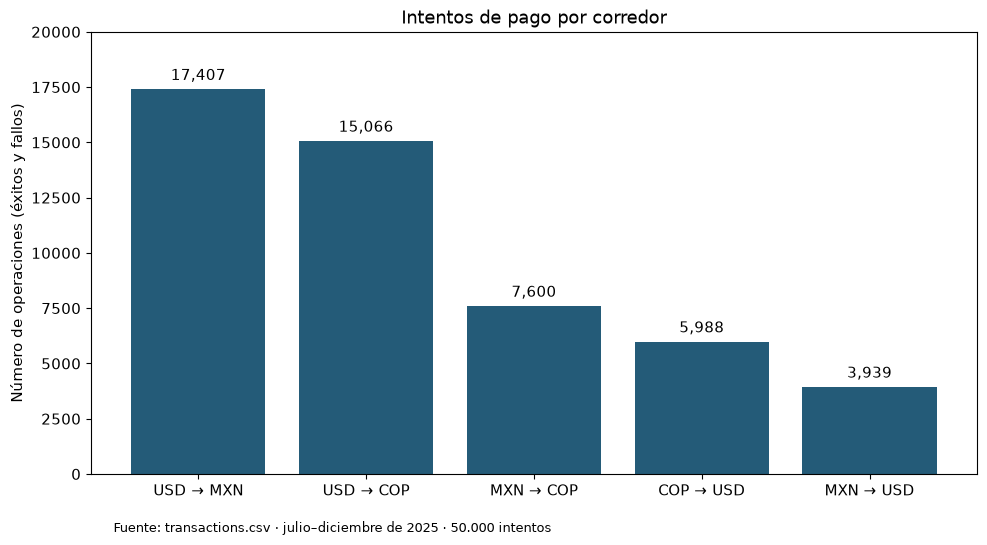

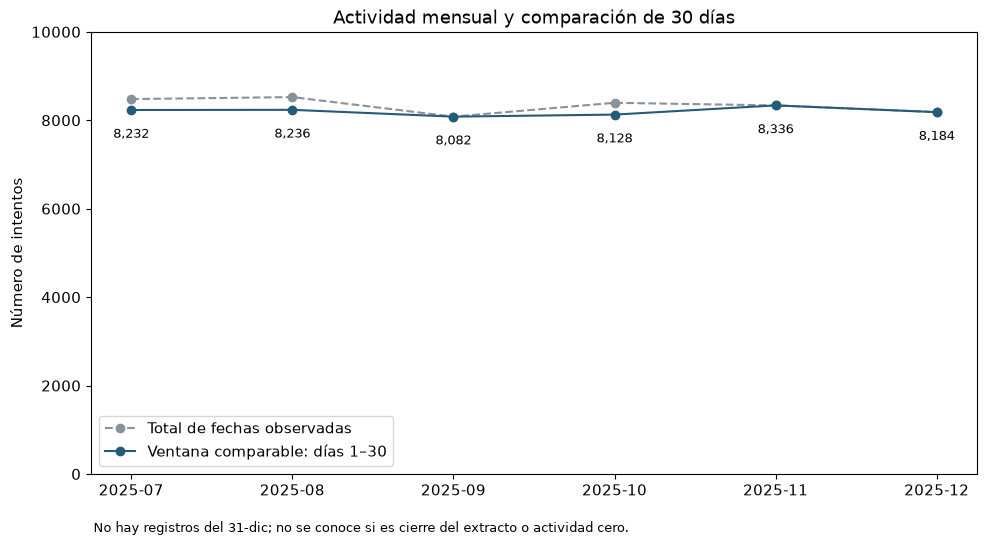

In [9]:
plt.rcParams.update({'font.size': 11})
fig, ax = plt.subplots(figsize=(10,5.5))
bars = ax.bar(top_corridors.corridor.str.replace('_',' → '),top_corridors.total_transactions,color='#245B78')
ax.bar_label(bars,labels=[f'{v:,}' for v in top_corridors.total_transactions],padding=4)
ax.set(title='Intentos de pago por corredor',ylabel='Número de operaciones (éxitos y fallos)',ylim=(0,20000))
fig.text(.12,.02,'Fuente: transactions.csv · julio–diciembre de 2025 · 50.000 intentos',fontsize=9)
fig.tight_layout(rect=[0,.05,1,1]);fig.savefig(ROOT/'corridor_volume.png',dpi=160);plt.show();plt.close(fig)
fig, ax = plt.subplots(figsize=(10,5.5))
ax.plot(monthly.month,monthly.total_transactions,marker='o',linestyle='--',color='#8B9198',label='Total de fechas observadas')
ax.plot(monthly.month,monthly.transactions_days_1_30,marker='o',color='#245B78',label='Ventana comparable: días 1–30')
for x,y in zip(monthly.month,monthly.transactions_days_1_30): ax.annotate(f'{y:,}',(x,y),xytext=(0,-20),textcoords='offset points',ha='center',fontsize=9)
ax.set(title='Actividad mensual y comparación de 30 días',ylabel='Número de intentos',ylim=(0,10000));ax.legend(loc='lower left')
fig.text(.10,.02,'No hay registros del 31-dic; no se conoce si es cierre del extracto o actividad cero.',fontsize=9)
fig.tight_layout(rect=[0,.05,1,1]);fig.savefig(ROOT/'monthly_trend.png',dpi=160);plt.show();plt.close(fig)

## 9. Exportación y controles finales
El control «Tres indicadores clave» comprueba solo dos comisiones y la meta de operaciones, no el documento completo.

Los valores se exportan sin redondear su precisión interna; los formatos controlan cómo se muestran. Tasas sin observaciones quedan vacías y se explican. La generación visual del Excel está separada del análisis y usa el script `export_excel.mjs` (instrucciones en README). La exportación no modifica datos fuente.

**Tablas de referencia en `cobre_analysis.xlsx`:**

- Tabla 19. Definiciones y limitaciones — hoja «Methodology».
- Tabla 20. Controles del análisis — hoja «Checks».

In [10]:
methodology = pd.DataFrame([
['Fuentes','transactions.csv y users.csv originales; 50.000 intentos y 5.000 usuarios.'],
['Segmento principal','users.user_segment para clientes. Sin historial, no se certifica el segmento histórico.'],
['Sensibilidad','transactions.user_segment se conserva por separado; 30.435 discrepancias.'],
['Cobertura','01-jul a 30-dic de 2025. El motivo de la ausencia del 31-dic no se conoce.'],
['Tiempo','Comparación principal: días 1–30 de cada mes. Se mantienen totales y promedio por día observado.'],
['Usuarios','Promedio sobre todos los registrados. Usuarios con operaciones no significa status activo.'],
['Top 10','Cantidad descendente, user_id ascendente. Cuatro usuarios con 21 y diez con 20.'],
['Comisiones','0,5% supuesto; promedio del semestre / 6; no ingreso contable ni margen neto.'],
['Objetivo 5%','Por conteo semestral: 870 fallos como máximo, 2.307 recuperaciones; ticket fallido medio.'],
['Sensibilidad financiera','Extremos por 2.307 menores/mayores importes. 5% del valor es un supuesto distinto.'],
['Horas','Hora original sin zona horaria informada; no se atribuye causalidad.'],
['Ausencias','Sin códigos de error, reintentos, tarifas reales, costos, demanda o mercado.'],
['Formato','Exportación estática de tablas; recalcular ejecutando el notebook y export_excel.mjs.'],
['IA','Codex apoyó la revisión de código, cálculos, interpretación y redacción.']
],columns=['Tema','Criterio'])
for name,digest in source_hashes.items():
    check('CSV intacto '+name, hashlib.sha256((ROOT/'data'/name).read_bytes()).hexdigest()==digest)
check('Reconciliación de volúmenes', top_corridors.total_transactions.sum()==monthly.total_transactions.sum()==country_analysis.total_transactions.sum()==len(t))
check('Tres indicadores clave', round(loss,2)==20921.00 and round(count_gain,2)==15191.93 and pilot_count==38)
check('Población con estados inactivos conservada', joined.status_user.eq('inactive').sum()==7526)
tables = {
'Corridor Volume':top_corridors,'Corridor Value':corridor_value,'Success Rates':corridor_success,
'Top Users':top_users,'Country Analysis':country_analysis,'Weekly':weekly,'Hourly':hourly,'Monthly':monthly,
'Failure Segments':failure_segments,'Failure Amounts':amount_analysis,'Failure Days':daily_failures,
'Financial Impact':financial_impact,'Corridor Growth':corridor_growth,
'Segment Audit':segment_audit,'Segment Sensitivity':segment_sensitivity,'Financial Scenarios':scenarios,
'Strategy':strategy,'Methodology':methodology,'Checks':pd.DataFrame(checks)}
payload = {name: json.loads(df.to_json(orient='split',index=False,date_format='iso',double_precision=15)) for name,df in tables.items()}
(ROOT/'analysis_results.json').write_text(json.dumps(payload,ensure_ascii=False,indent=2),encoding='utf-8')
display(pd.DataFrame(checks))
print('Validaciones completas. Tablas en analysis_results.json; gráficos actualizados. Exportar Excel con export_excel.mjs.')
con.close()

,Control,Resultado,Detalle
0,Filas originales,OK,
1,Sin nulos,OK,
2,IDs únicos,OK,
3,JOIN sin pérdida ni multiplicación,OK,
4,Estados permitidos,OK,
5,Segmentos permitidos,OK,
6,País de usuario permitido,OK,
7,Importes positivos finitos con centavos,OK,
8,Registro anterior a operación,OK,
9,Corredor y países consistentes,OK,


Validaciones completas. Tablas en analysis_results.json; gráficos actualizados. Exportar Excel con export_excel.mjs.
